In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:42158")
client

<Client: 'tcp://127.0.0.1:42158' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import geostrokit as qg

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
dsp = xr.open_zarr(op.join(ddir,"QG/eddy/qPsi.zarr"))
dsp

<xarray.Dataset> Size: 60GB
Dimensions:  (time: 718, level: 5, y: 1025, x: 2049)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.856e+09 1.858e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
  * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
Data variables:
    pp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
    qp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>

In [5]:
N2 = xr.DataArray(np.array([4.04e-05, 1.6e-05, 1.24e-05, 2.52e-06,]), 
                  dims="li",
                  coords={"li":np.array([0.5,1.5,2.5,3.5])}
                 )
dz = xr.DataArray(np.array([250,250,250,250,3000]), 
                  dims="level",
                  coords={"level":dsp.level.data}
                 )
Zp1 = np.concatenate((np.array([0.,]), -np.cumsum(dz.data)))
Z = .5*(Zp1[1:]+Zp1[:-1])
print(N2,Z,Zp1)

dsp["Zp1"] = xr.DataArray(Zp1, dims="lp1",
                          coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                         )
dsp["Z"] = xr.DataArray(Z, dims="level",
                        coords={"level":dsp.level.data}
                       )
dsp["N2"] = N2

# llo, lla = np.meshgrid(dsp.x, dsp.y)
# xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
#                   coords={"y":dsp.y.data,
#                           "xG":.5*(dsp.x.data[1:]+dsp.x.data[:-1])}
#                  )
# yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
#                   coords={"yG":.5*(dsp.y.data[1:]+dsp.y.data[:-1]),
#                           "x":dsp.x.data}
#                  )
dsp.coords["yG"] = ("yG",.5*(dsp.y.data[1:]+dsp.y.data[:-1]))
dsp.coords["xG"] = ("xG",.5*(dsp.x.data[1:]+dsp.x.data[:-1]))

grid = Grid(dsp, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
            autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1", "inner": "li"}
                   })

dsp, grid

<xarray.DataArray (li: 4)> Size: 32B
array([4.04e-05, 1.60e-05, 1.24e-05, 2.52e-06])
Coordinates:
  * li       (li) float64 32B 0.5 1.5 2.5 3.5 [ -125.  -375.  -625.  -875. -2500.] [    0.  -250.  -500.  -750. -1000. -4000.]


(<xarray.Dataset> Size: 60GB
 Dimensions:  (time: 718, level: 5, y: 1025, x: 2049, lp1: 6, li: 4, yG: 1024,
               xG: 2048)
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.856e+09 1.858e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
   * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
   * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
   * li       (li) float64 32B 0.5 1.5 2.5 3.5
   * yG       (yG) float32 4kB 1.953e+03 5.859e+03 ... 3.994e+06 3.998e+06
   * xG       (xG) float32 8kB 1.953e+03 5.859e+03 ... 7.994e+06 7.998e+06
 Data variables:
     pp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
     qp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
     Zp1      (lp1) float64 48B 0.0 -250.0 -500.0 -750.0 -1e+03 -4e+03
     Z        (level) 

In [6]:
print(dsp.x.diff("x").mean().values, dsp.y.diff("y").mean().values)
print(dsp.xG.diff("xG").mean().values, dsp.yG.diff("yG").mean().values)

3906.25 3906.25
3906.2502 3906.2502


In [7]:
Delta = 3.90625e+03
up = -(grid.diff(dsp.pp.fillna(0.).chunk({"y":-1}),"Y",padding="extend") 
       / Delta)
vp = (grid.diff(dsp.pp.fillna(0.).chunk({"x":-1}),"X",padding="extend") 
      / Delta)
uq = (grid.interp(up,"Y",padding="extend")
      * dsp.qp).mean("time")
vq = (grid.interp(vp,"X",padding="extend")
      * dsp.qp).mean("time")

# il = 0
# up, vp = qg.comp_vel(dsp.pp.isel(level=il).values, Delta, 'dirichlet_face')
# up = xr.DataArray(up, dims=dsp.pp.isel(level=il).dims, 
#                   coords=dsp.pp.isel(level=il).coords
#                  ).chunk(dsp.pp.isel(level=il).chunks)
# vp = xr.DataArray(vp, dims=dsp.pp.isel(level=il).dims, 
#                   coords=dsp.pp.isel(level=il).coords
#                  ).chunk(dsp.pp.isel(level=il).chunks)
# print(up, vp)
# uq = (up * dsp.qp.isel(level=il)).mean("time").compute()
# vq = (vp * dsp.qp.isel(level=il)).mean("time").compute()
uq, vq

(<xarray.DataArray (level: 5, y: 1025, x: 2049)> Size: 42MB
 dask.array<mean_agg-aggregate, shape=(5, 1025, 2049), dtype=float32, chunksize=(1, 125, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
   * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06,
 <xarray.DataArray (level: 5, y: 1025, x: 2049)> Size: 42MB
 dask.array<mean_agg-aggregate, shape=(5, 1025, 2049), dtype=float32, chunksize=(1, 125, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
   * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06)

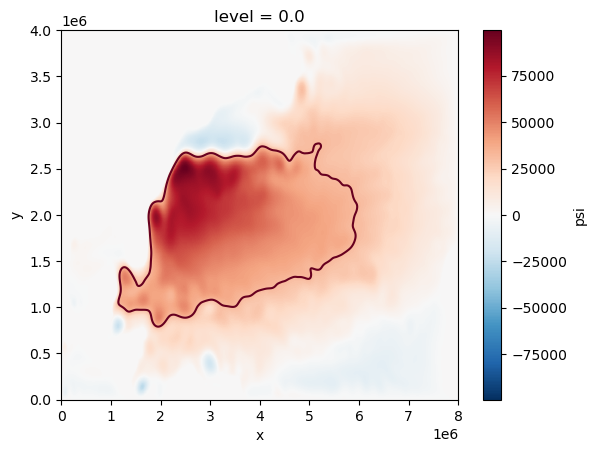

In [12]:
dsb = xr.open_zarr(op.join(ddir,"QG/mean/qPsi.zarr"))
dsb.psi.isel(level=0).plot(rasterized=True)
dsb.psi.isel(level=0).plot.contour(levels=np.array([3.2e4]))

In [10]:
dsin = xr.open_dataset(op.join(ddir,"QG/input_vars_5l_N2048.nc")
                      ).isel(t=0)
mask = dsin.mask
try:
  mask0 = dsin.mask0
except:
  mask0 = dsin.coastlines

mask0_nan = np.where(mask0 == 0, np.nan, 1)
mask0_c_nan = mask0_nan[:-1,:-1]

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 16.86 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


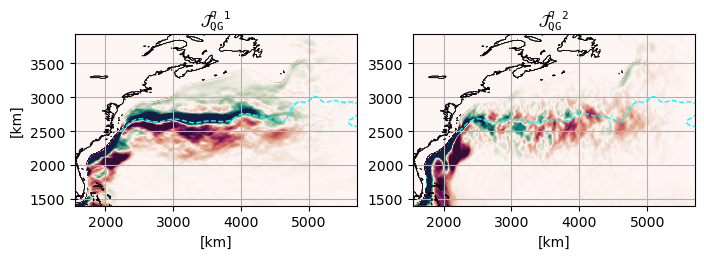

In [13]:
xmax = 5700
xmin = 1550
ymin = 1400
ymax = 3930

fig, axes = plt.subplots(figsize=(8,4), nrows=1, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0]
ax2 = axes[1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )

ax1.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               uq.isel(level=0), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-4e-6, vmax=4e-6,
               zorder=0,
               # rasterized=True
              )
ax2.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               vq.isel(level=0), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-4e-6, vmax=4e-6,
               zorder=0,
               # rasterized=True
              )

ax1.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="cyan", linestyles="dashed", linewidths=1)
ax2.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="cyan", linestyles="dashed", linewidths=1)

ax1.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax2.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

ax1.set_rasterized(True)
ax2.set_rasterized(True)

ax1.set_xlabel(r"[km]")
ax2.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
ax1.set_aspect("equal")
ax2.set_aspect("equal")

ax1.grid(True)
ax2.grid(True)

ax1.set_title(r"${\mathcal{J}^{q}_{\tt QG}}^1$", 
              fontsize=11)
ax2.set_title(r"${\mathcal{J}^{q}_{\tt QG}}^2$", 
              fontsize=11)

# cb = fig.colorbar(im, ax=axes, shrink=.6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/PVflux_QGsurf.pdf"), dpi=200)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 16.86 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


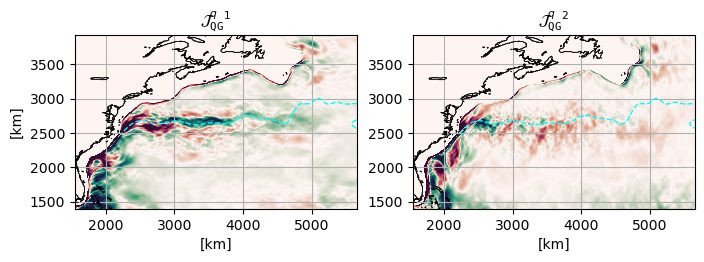

In [54]:
xmax = 5650
xmin = 1550
ymin = 1400
ymax = 3930

fig, axes = plt.subplots(figsize=(8,4), nrows=1, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0]
ax2 = axes[1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )

ax1.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               uq.isel(level=1), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-.24e-6, vmax=.24e-6,
               zorder=0,
               # rasterized=True
              )
ax2.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               vq.isel(level=1), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-.24e-6, vmax=.24e-6,
               zorder=0,
               # rasterized=True
              )

ax1.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="cyan", linestyles="dashed", linewidths=1)
ax2.contour(dsb.x*1e-3, dsb.y*1e-3, 
            dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
            levels=np.array([2.84e4,]), 
            colors="cyan", linestyles="dashed", linewidths=1)

ax1.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax2.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

ax1.set_rasterized(True)
ax2.set_rasterized(True)

ax1.set_xlabel(r"[km]")
ax2.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
ax1.set_aspect("equal")
ax2.set_aspect("equal")

ax1.grid(True)
ax2.grid(True)

ax1.set_title(r"${\mathcal{J}^{q}_{\tt QG}}^1$", 
              fontsize=11)
ax2.set_title(r"${\mathcal{J}^{q}_{\tt QG}}^2$", 
              fontsize=11)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/PVflux_QG.pdf"), dpi=200)

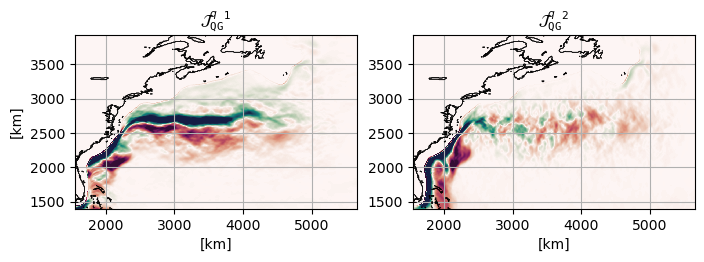

In [12]:
xmax = 5650
xmin = 1550
ymin = 1400
ymax = 3930

fig, axes = plt.subplots(figsize=(8,4), nrows=1, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0]
ax2 = axes[1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )

im = ax1.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               uq, 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-6e-6, vmax=6e-6,
               zorder=0,
               # rasterized=True
              )
ax2.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               vq, 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-6e-6, vmax=6e-6,
               zorder=0,
               # rasterized=True
              )

ax1.contour(dsb.x, dsb.y, dsb.psi.where(sshb.y>2500e3), 
            levels=np.array([0.,]), 
            colors="cyan", linestyles="dashed", linewidths=1)
ax2.contour(dsb.x, dsb.y, dsb.psi.where(sshb.y>2500e3), 
            levels=np.array([0.,]), 
            colors="cyan", linestyles="dashed", linewidths=1)

ax1.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax2.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

ax1.set_rasterized(True)
ax2.set_rasterized(True)

ax1.set_xlabel(r"[km]")
ax2.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
ax1.set_aspect("equal")
ax2.set_aspect("equal")

ax1.grid(True)
ax2.grid(True)

ax1.set_title(r"${\mathcal{J}^{q}_{\tt QG}}^1$", 
              fontsize=11)
ax2.set_title(r"${\mathcal{J}^{q}_{\tt QG}}^2$", 
              fontsize=11)

# cb = fig.colorbar(im, ax=axes, shrink=.6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/PVflux_QGsurf_geostrokit.pdf"), dpi=200)

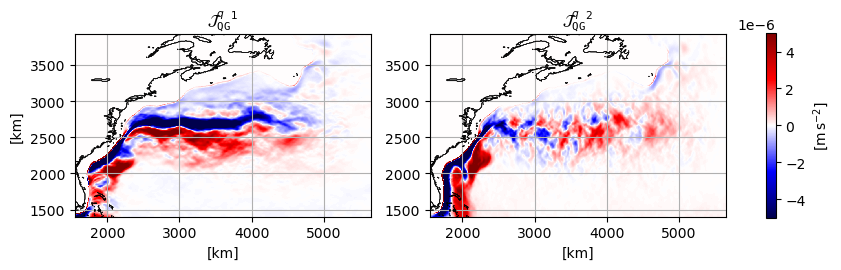

In [28]:
xmax = 5650
xmin = 1550
ymin = 1400
ymax = 3930

fig, axes = plt.subplots(figsize=(10.5,4), nrows=1, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0]
ax2 = axes[1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )

im = ax1.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               uq, 
               cmap="seismic",
               # cmap="RdBu_r",
               vmin=-5e-6, vmax=5e-6,
               zorder=0,
               # rasterized=True
              )
ax2.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               vq, 
               cmap="seismic",
               # cmap="RdBu_r",
               vmin=-5e-6, vmax=5e-6,
               zorder=0,
               # rasterized=True
              )

ax1.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax2.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

ax1.set_rasterized(True)
ax2.set_rasterized(True)

ax1.set_xlabel(r"[km]")
ax2.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
ax1.set_aspect("equal")
ax2.set_aspect("equal")

ax1.grid(True)
ax2.grid(True)

ax1.set_title(r"${\mathcal{J}^{q}_{\tt QG}}^1$", 
              fontsize=11)
ax2.set_title(r"${\mathcal{J}^{q}_{\tt QG}}^2$", 
              fontsize=11)

cb = fig.colorbar(im, ax=axes, shrink=.6)
cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/PVflux_QGsurf_geostrokit-seismic.pdf"), dpi=200)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 16.86 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


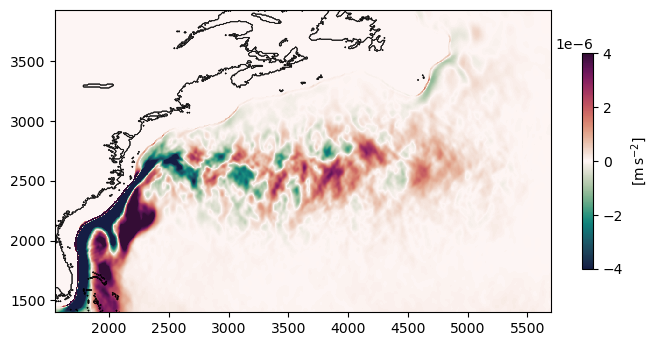

In [10]:
xmax = 5700
xmin = 1550
ymin = 1400
ymax = 3930

fig = plt.figure(figsize=(8,4))
ax6 = fig.add_subplot(1, 1, 1)
ax6.set_xlim([xmin, xmax], )
ax6.set_ylim([ymin, ymax], )

im = ax6.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
                vq.isel(level=0), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-4e-6, vmax=4e-6,
               rasterized=True)

ax6.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

cb = fig.colorbar(im, ax=ax6, shrink=.7)
cb.set_label(r"[m$\,$s$^{-2}$]")

ax6.set_rasterized(True)
ax6.set_aspect("equal")

plt.savefig(op.join(ddir,"Figs/PVflux_QG_cbar.pdf"))

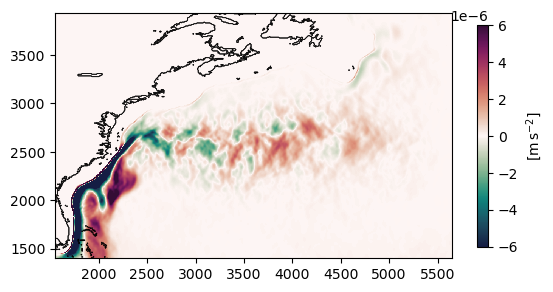

In [13]:
fig = plt.figure()
ax6 = fig.add_subplot(1, 1, 1)
ax6.set_xlim([xmin, xmax], )
ax6.set_ylim([ymin, ymax], )

im = ax6.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
                vq, 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-6e-6, vmax=6e-6,
               rasterized=True)

ax6.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

cb = fig.colorbar(im, ax=ax6, shrink=.6)
cb.set_label(r"[m$\,$s$^{-2}$]")

ax6.set_rasterized(True)
ax6.set_aspect("equal")

plt.savefig(op.join(ddir,"Figs/PVflux_QGgeostrokit_cbar.pdf"))